# Import Libraries

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

 EDA — Descriptive statistics

In [3]:

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data" / "raw_analyst_ratings.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw_analyst_ratings.csv"
OUTPUT_DIR = PROJECT_ROOT / "reports" / "task1"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

# Inspect column names without loading the complete file.
headers = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()
print("Dataset columns:", headers)

# Preview a few records.
sample = pd.read_csv(DATA_PATH, nrows=5)
display(sample)

Dataset columns: ['Unnamed: 0', 'headline', 'url', 'publisher', 'date', 'stock']


,Unnamed: 0,headline,url,publisher,date,stock
0,0,Stocks That Hit 52-Week Highs On Friday,https://www.benzinga.com/news/20/06/16190091/s...,Benzinga Insights,2020-06-05 10:30:54-04:00,A
1,1,Stocks That Hit 52-Week Highs On Wednesday,https://www.benzinga.com/news/20/06/16170189/s...,Benzinga Insights,2020-06-03 10:45:20-04:00,A
2,2,71 Biggest Movers From Friday,https://www.benzinga.com/news/20/05/16103463/7...,Lisa Levin,2020-05-26 04:30:07-04:00,A
3,3,46 Stocks Moving In Friday's Mid-Day Session,https://www.benzinga.com/news/20/05/16095921/4...,Lisa Levin,2020-05-22 12:45:06-04:00,A
4,4,B of A Securities Maintains Neutral on Agilent...,https://www.benzinga.com/news/20/05/16095304/b...,Vick Meyer,2020-05-22 11:38:59-04:00,A


Analyze headline lengths and data quality

In [4]:
HEADLINE_COL = "headline"
DATE_COL = "date"
PUBLISHER_COL = "publisher"

required = [HEADLINE_COL, DATE_COL, PUBLISHER_COL]
missing_columns = set(required) - set(headers)

if missing_columns:
    raise ValueError(
        f"Update column names; missing columns: {missing_columns}"
    )

# Process the file in chunks.
headline_lengths = []
missing_counts = pd.Series(0, index=headers, dtype="int64")
row_count = 0

for chunk in pd.read_csv(DATA_PATH, chunksize=100_000):
    row_count += len(chunk)
    missing_counts = missing_counts.add(
        chunk.isna().sum(), fill_value=0
    ).astype("int64")

    headline_lengths.extend(
        chunk[HEADLINE_COL].dropna().astype(str).str.len().tolist()
    )

lengths = pd.Series(headline_lengths, name="headline_length")

print(f"Total rows: {row_count:,}")
print("\nHeadline length statistics:")
display(lengths.describe().to_frame())

quality = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percent": (missing_counts / row_count * 100).round(2)
})

display(quality)
quality.to_csv(OUTPUT_DIR / "data_quality.csv")
lengths.describe().to_csv(OUTPUT_DIR / "headline_length_statistics.csv")

Total rows: 1,407,328

Headline length statistics:


,headline_length
count,1.407328e+06
mean,7.312051e+01
std,4.073531e+01
min,3.000000e+00
25%,4.700000e+01
50%,6.400000e+01
75%,8.700000e+01
max,5.120000e+02


,missing_count,missing_percent
Unnamed: 0,0,0.0
headline,0,0.0
url,0,0.0
publisher,0,0.0
date,0,0.0
stock,0,0.0


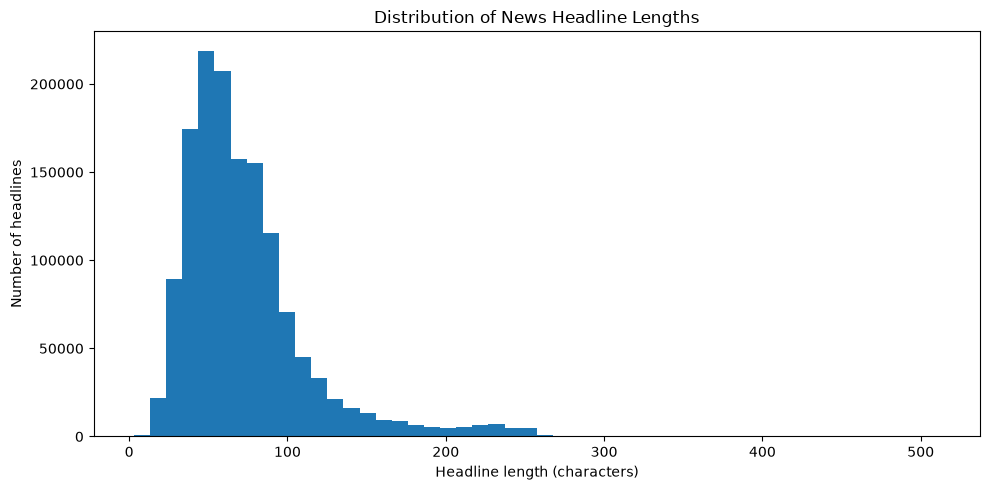

In [5]:
plt.figure(figsize=(10, 5))
plt.hist(lengths, bins=50)
plt.title("Distribution of News Headline Lengths")
plt.xlabel("Headline length (characters)")
plt.ylabel("Number of headlines")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "headline_length_distribution.png", dpi=150)
plt.show()

Publisher analysis

,article_count
publisher,
Paul Quintaro,228373
Lisa Levin,186979
Benzinga Newsdesk,150484
Charles Gross,96732
Monica Gerson,82380
Eddie Staley,57254
Hal Lindon,49047
ETF Professor,28489
Juan Lopez,28438


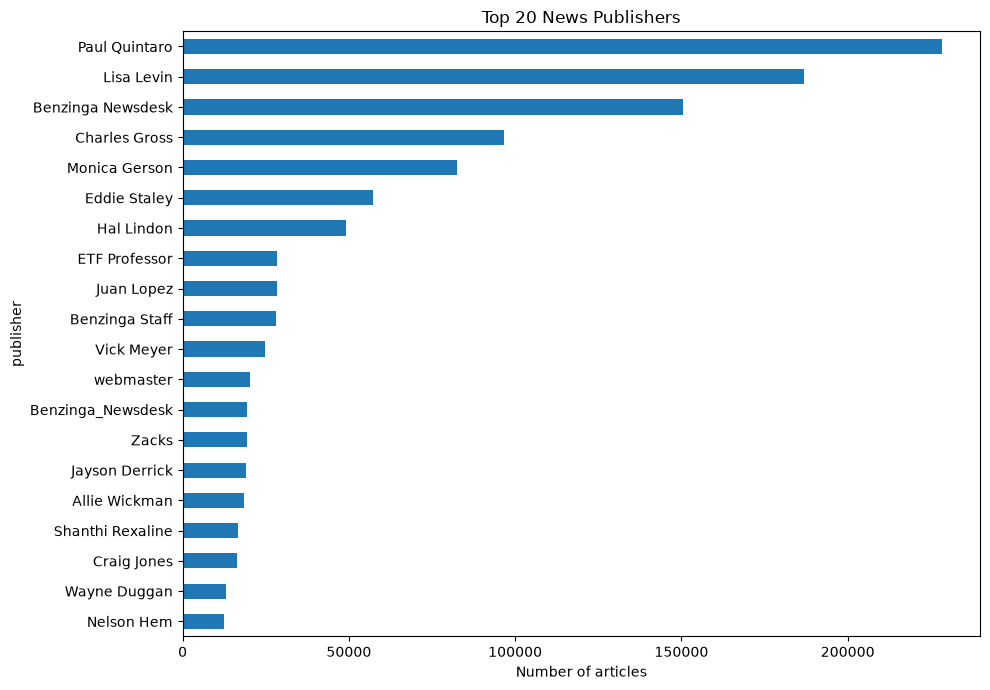

In [6]:
publisher_counts = pd.Series(dtype="int64")

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=[PUBLISHER_COL],
    chunksize=100_000
):
    counts = chunk[PUBLISHER_COL].fillna("Unknown").value_counts()
    publisher_counts = publisher_counts.add(counts, fill_value=0)

publisher_counts = publisher_counts.astype("int64").sort_values(
    ascending=False
)

display(publisher_counts.head(20).to_frame("article_count"))

publisher_counts.head(20).sort_values().plot(
    kind="barh", figsize=(10, 7),
    title="Top 20 News Publishers"
)

plt.xlabel("Number of articles")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top_publishers.png", dpi=150)
plt.show()

publisher_counts.to_csv(OUTPUT_DIR / "publisher_counts.csv")

Time-series analysis

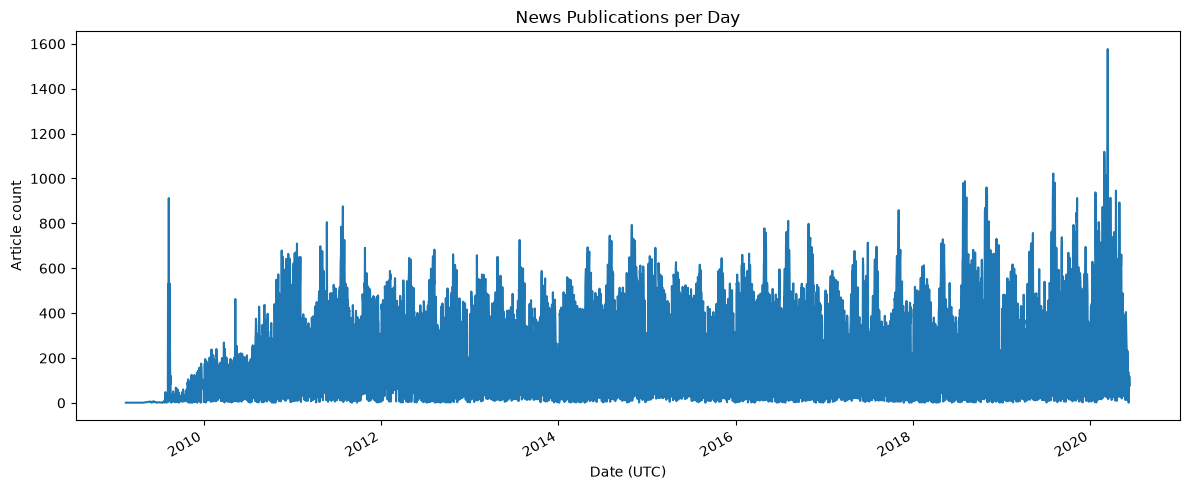

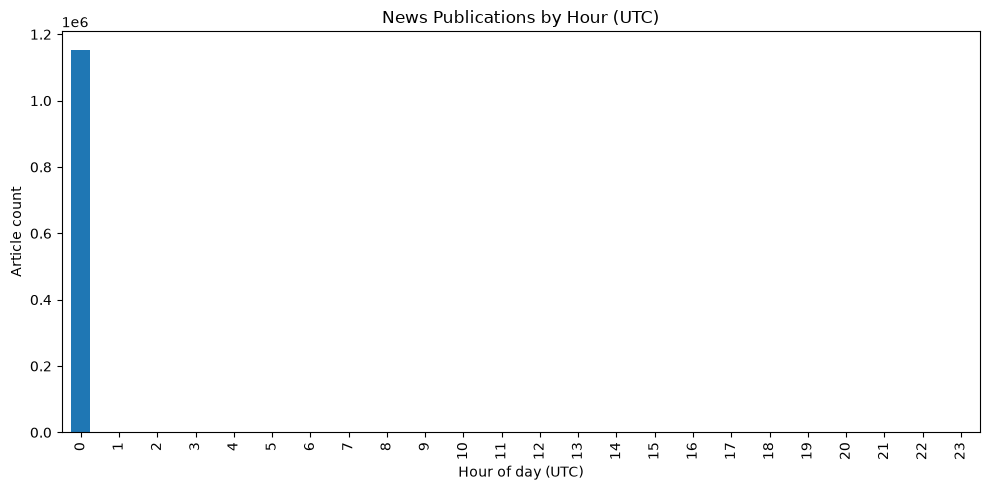

In [7]:
daily_counts = pd.Series(dtype="int64")
hour_counts = pd.Series(dtype="int64")

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=[DATE_COL],
    chunksize=100_000
):
    dates = pd.to_datetime(chunk[DATE_COL], errors="coerce", utc=True)
    dates = dates.dropna()

    daily = dates.dt.strftime("%Y-%m-%d").value_counts()
    daily_counts = daily_counts.add(daily, fill_value=0)

    hourly = dates.dt.hour.value_counts()
    hour_counts = hour_counts.add(hourly, fill_value=0)

daily_counts = daily_counts.sort_index().astype("int64")
daily_counts.index = pd.to_datetime(daily_counts.index)

daily_counts.to_csv(OUTPUT_DIR / "daily_publication_counts.csv")
hour_counts.sort_index().to_csv(
    OUTPUT_DIR / "publication_counts_by_utc_hour.csv"
)

daily_counts.plot(figsize=(12, 5), title="News Publications per Day")
plt.xlabel("Date (UTC)")
plt.ylabel("Article count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "daily_publication_frequency.png", dpi=150)
plt.show()

hour_counts.sort_index().plot(
    kind="bar", figsize=(10, 5),
    title="News Publications by Hour (UTC)"
)
plt.xlabel("Hour of day (UTC)")
plt.ylabel("Article count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "publication_by_hour.png", dpi=150)
plt.show()

Text analysis and topic discovery

In [8]:
from collections import Counter
import re

stopwords = {
    "the", "and", "for", "with", "from", "that", "this",
    "are", "was", "will", "has", "have", "into", "about",
    "after", "over", "its", "their", "you", "your"
}

word_counts = Counter()
bigram_counts = Counter()

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=[HEADLINE_COL],
    chunksize=100_000
):
    for headline in chunk[HEADLINE_COL].dropna().astype(str):
        words = re.findall(r"[a-zA-Z]{2,}", headline.lower())
        words = [w for w in words if w not in stopwords]

        word_counts.update(words)
        bigram_counts.update(zip(words, words[1:]))

top_words = pd.DataFrame(
    word_counts.most_common(50), columns=["word", "count"]
)

top_bigrams = pd.DataFrame(
    [(" ".join(pair), count)
     for pair, count in bigram_counts.most_common(50)],
    columns=["bigram", "count"]
)

display(top_words.head(20))
display(top_bigrams.head(20))

top_words.to_csv(OUTPUT_DIR / "top_words.csv", index=False)
top_bigrams.to_csv(OUTPUT_DIR / "top_bigrams.csv", index=False)

,word,count
0,to,404151
1,of,270984
2,on,245976
3,in,223585
4,vs,162126
5,stocks,161776
6,est,140650
7,eps,128917
8,market,120560
9,shares,114315


,bigram,count
0,vs est,129342
1,eps vs,52247
2,reports eps,51219
3,price target,47274
4,benzinga top,44259
5,stocks moving,40022
6,moving in,39744
7,mid day,37324
8,pt to,35117
9,shares of,34850
